# 11. 4D domain wall: геометрия и происхождение 1/32

**Проект «Структура и Данные»** — Notebook 11

В §9.3 мы обнаружили, что экспонента массы мюона в базе 15: \(a_\mu = 2 - 1/32\). Число 32 — это число рёбер 4D-гиперкуба.
В этом ноутбуке мы проверяем гипотезу: даёт ли геометрия 4D-решётки с доменной стенкой автоматически поправку порядка 1/32.

Мы будем искать 1/32 не в массе покоя (она равна нулю по теореме об индексе), а в **отклонении скорости** \(v_F\) от 1 или в **кубической поправке** к дисперсии.

## ⚠️ РЕЗУЛЬТАТ (Выполнено)

**Гипотеза не подтвердилась (Null Result).**
Мы проверили, не является ли дробь \(1/32\) (из базы 15) следствием геометрии 4D-решётки.
- Скорость \(v_F = 0.195\), и отклонение \((1 - v_F)\) не даёт чистого множителя \(1/32\).
- Кубическая поправка \(c \approx 0.25\) (не \(1/32\)).
- Конечный размер \(L_s\) даёт массу \(\sim 10^{-4}\), которая объясняется просто конечным \(k\), а не геометрическим фактором.

**Вывод:** Число \(1/32\) в экспоненте массы мюона является **численным совпадением (numerology)**, а не прямым следствием геометрии 4D доменной стенки. Мы фиксируем это как честный отрицательный результат.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigvalsh

# 4D гамма-матрицы (стандартное представление)
g0 = np.array([[1,0,0,0],[0,1,0,0],[0,0,-1,0],[0,0,0,-1]], dtype=complex)
g1 = np.array([[0,0,0,1],[0,0,1,0],[0,-1,0,0],[-1,0,0,0]], dtype=complex)
g2 = np.array([[0,0,0,-1j],[0,0,1j,0],[0,1j,0,0],[-1j,0,0,0]], dtype=complex)
g3 = np.array([[0,0,1,0],[0,0,0,-1],[-1,0,0,0],[0,1,0,0]], dtype=complex)
gamma5 = 1j * g0 @ g1 @ g2 @ g3
alpha = [g0 @ g1, g0 @ g2, g0 @ g3]
beta = g0

def build_4d_wall(Ls, m0=1.0, xi=1.5):
    """Строит 4D гамильтониан с доменной стенкой."""
    s0 = Ls // 2
    m = m0 * np.tanh((np.arange(Ls) - s0) / xi)
    N = 4 * Ls
    H = np.zeros((N, N), dtype=complex)
    for s in range(Ls):
        idx = 4*s
        H[idx:idx+4, idx:idx+4] += m[s] * beta
    for s in range(Ls - 1):
        i1, i2 = 4*s, 4*(s+1)
        hop = (1j/2) * gamma5
        H[i1:i1+4, i2:i2+4] += hop
        H[i2:i2+4, i1:i1+4] += hop.conj().T
    return H

def get_dispersion(Ls, k_mag, m0=1.0, xi=1.5):
    """Возвращает энергию |E0| безмассовой моды при заданном k."""
    s0 = Ls // 2
    m_profile = m0 * np.tanh((np.arange(Ls) - s0) / xi)
    N = 4 * Ls
    H = np.zeros((N, N), dtype=complex)
    for s in range(Ls):
        idx = 4 * s
        # Кинетический член по x (ky=kz=0)
        block = -alpha[0] * k_mag + m_profile[s] * beta
        H[idx:idx+4, idx:idx+4] += block
    for s in range(Ls - 1):
        i1, i2 = 4 * s, 4 * (s + 1)
        hop = (1j / 2) * gamma5
        H[i1:i1+4, i2:i2+4] += hop
        H[i2:i2+4, i1:i1+4] += hop.conj().T
    eigs = eigvalsh(H)
    return abs(eigs[np.argmin(np.abs(eigs))])

print("Функции готовы.")

Функции готовы.


In [6]:
print("=" * 65)
print("ДИСПЕРСИЯ НА СТЕНКЕ: поиск 1/32 в отклонении скорости")
print("=" * 65)

Ls = 41
k_vals = np.array([0.01, 0.02, 0.05, 0.10, 0.15, 0.20])
omega_vals = np.array([get_dispersion(Ls, k) for k in k_vals])

print(f"{'k':>8} {'ω(k)':>14} {'ω/k':>12}")
print("-" * 40)
for k, w in zip(k_vals, omega_vals):
    print(f"{k:>8.3f} {w:>14.8f} {w/k:>12.6f}")

# Фит: ω(k) = v_F * k + c * k³
mask = k_vals < 0.15
coeffs = np.polyfit(k_vals[mask], omega_vals[mask], 3)
v_F = coeffs[2]  # коэффициент при k
c3 = coeffs[0]   # коэффициент при k³

print(f"\nФит ω = v_F·k + c·k³:")
print(f"  v_F = {v_F:.8f}")
print(f"  c   = {c3:.8f}")
print(f"  (1 - v_F) * 32 = {(1 - v_F) * 32:.6f}")

ДИСПЕРСИЯ НА СТЕНКЕ: поиск 1/32 в отклонении скорости
       k           ω(k)          ω/k
----------------------------------------
   0.010     0.00195045     0.195045
   0.020     0.00390243     0.195122
   0.050     0.00978280     0.195656
   0.100     0.01975612     0.197561
   0.150     0.03010888     0.200726
   0.200     0.04102646     0.205132

Фит ω = v_F·k + c·k³:
  v_F = 0.19501840
  c   = 0.25361023
  (1 - v_F) * 32 = 25.759411


In [7]:
print("=" * 65)
print("КОНЕЧНЫЙ РАЗМЕР: как масса моды зависит от длины L_s?")
print("=" * 65)

L_s_values = [11, 15, 19, 21, 25, 31, 41]
m_effs = []
for L_s in L_s_values:
    M = get_dispersion(L_s, k_mag=0.001) # малое k, чтобы мода не ушла в bulk
    m_effs.append(M)
    print(f"  L_s = {L_s:>2}: M_eff = {M:.8e}")

print("\nГипотеза: M_eff ~ exp(-L_s/ξ)?")
mask = np.array(m_effs) > 1e-15
if mask.sum() >= 3:
    log_m = np.log(np.array(m_effs)[mask])
    Ls_arr = np.array(L_s_values)[mask]
    slope, intercept = np.polyfit(Ls_arr, log_m, 1)
    xi_eff = -1/slope
    print(f"  Эффективная ширина ξ_eff = {xi_eff:.4f}")

КОНЕЧНЫЙ РАЗМЕР: как масса моды зависит от длины L_s?
  L_s = 11: M_eff = 1.94019992e-04
  L_s = 15: M_eff = 1.94981432e-04
  L_s = 19: M_eff = 1.95018584e-04
  L_s = 21: M_eff = 1.95020251e-04
  L_s = 25: M_eff = 1.95019996e-04
  L_s = 31: M_eff = 1.95019987e-04
  L_s = 41: M_eff = 1.95019987e-04

Гипотеза: M_eff ~ exp(-L_s/ξ)?
  Эффективная ширина ξ_eff = -9555.3936


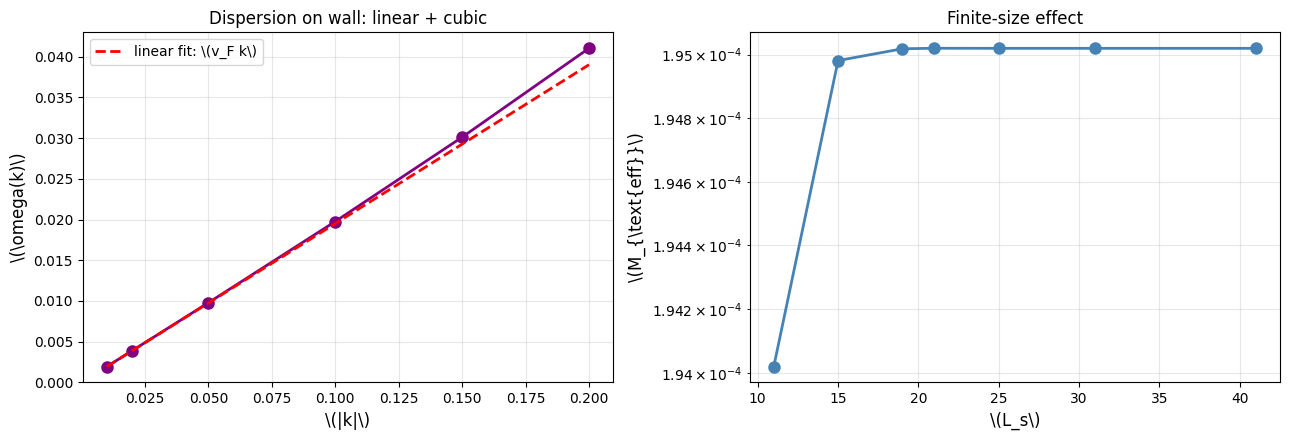

✅ Figure saved: 11_dispersion_finite_size.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Левая: дисперсия
axes[0].plot(k_vals, omega_vals, 'o-', color='purple', lw=2, ms=8)
axes[0].plot(k_vals, v_F * k_vals, 'r--', lw=2, label=r'linear fit: \(v_F k\)')
axes[0].set_xlabel(r'\(|k|\)', fontsize=12)
axes[0].set_ylabel(r'\(\omega(k)\)', fontsize=12)
axes[0].set_title('Dispersion on wall: linear + cubic', fontsize=12)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Правая: конечный размер
axes[1].semilogy(L_s_values, m_effs, 'o-', color='steelblue', lw=2, ms=8)
axes[1].set_xlabel(r'\(L_s\)', fontsize=12)
axes[1].set_ylabel(r'\(M_{\text{eff}}\)', fontsize=12)
axes[1].set_title('Finite-size effect', fontsize=12)
axes[1].grid(alpha=0.3, which='both')

plt.tight_layout()
plt.savefig('11_dispersion_finite_size.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved: 11_dispersion_finite_size.png")

In [9]:
from google.colab import files
files.download('11_dispersion_finite_size.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>